In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

print(df.shape)
df.head().round(2)

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.12,0.28,0.30,0.15,0.24,0.08,...,17.33,184.60,2019.0,0.16,0.67,0.71,0.27,0.46,0.12,0
1,20.57,17.77,132.90,1326.0,0.08,0.08,0.09,0.07,0.18,0.06,...,23.41,158.80,1956.0,0.12,0.19,0.24,0.19,0.28,0.09,0
2,19.69,21.25,130.00,1203.0,0.11,0.16,0.20,0.13,0.21,0.06,...,25.53,152.50,1709.0,0.14,0.42,0.45,0.24,0.36,0.09,0
3,11.42,20.38,77.58,386.1,0.14,0.28,0.24,0.11,0.26,0.10,...,26.50,98.87,567.7,0.21,0.87,0.69,0.26,0.66,0.17,0
4,20.29,14.34,135.10,1297.0,0.10,0.13,0.20,0.10,0.18,0.06,...,16.67,152.20,1575.0,0.14,0.20,0.40,0.16,0.24,0.08,0


In [2]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns='target')
y = df['target']

# 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(398, 30) (171, 30)


In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Train and compare three models
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=10, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision': precision_score(y_test, predicted, pos_label=0),
        'Recall': recall_score(y_test, predicted, pos_label=0),
        'F1': f1_score(y_test, predicted, pos_label=0)
    })

pd.DataFrame(results).round(2)

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.92,0.89,0.89,0.89
1,Random Forest,0.93,0.89,0.92,0.91
2,Gradient Boosting,0.95,0.95,0.91,0.93


In [4]:
from sklearn.model_selection import GridSearchCV

# Try different Random Forest settings
params = {
    'n_estimators': [10, 25, 50],
    'max_depth': [None, 3, 5],
    'min_samples_leaf': [1, 3, 5]
}

search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=5,
    scoring='accuracy'
)

search.fit(X_train, y_train)

print('Best parameters:', search.best_params_)
print('CV accuracy:', round(search.best_score_, 2))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 25}
CV accuracy: 0.97


In [5]:
# Evaluate the tuned Random Forest
best_forest = search.best_estimator_
best_pred = best_forest.predict(X_test)

print('Accuracy:', round(accuracy_score(y_test, best_pred), 2))
print('Precision:', round(precision_score(y_test, best_pred, pos_label=0), 2))
print('Recall:', round(recall_score(y_test, best_pred, pos_label=0), 2))
print('F1:', round(f1_score(y_test, best_pred, pos_label=0), 2))

Accuracy: 0.94
Precision: 0.94
Recall: 0.91
F1: 0.92


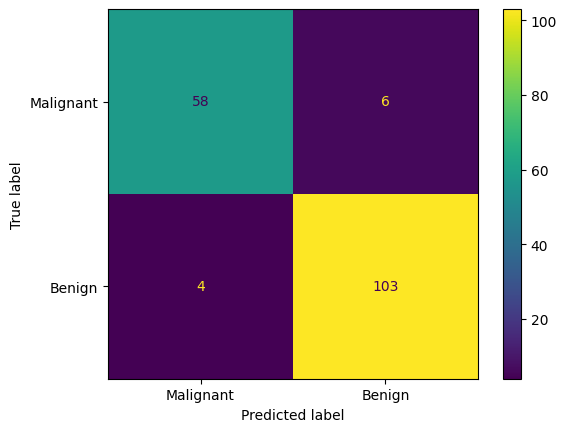

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as mat

# Show correct and incorrect predictions
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    labels=[0, 1],
    display_labels=['Malignant', 'Benign']
)

mat.show()

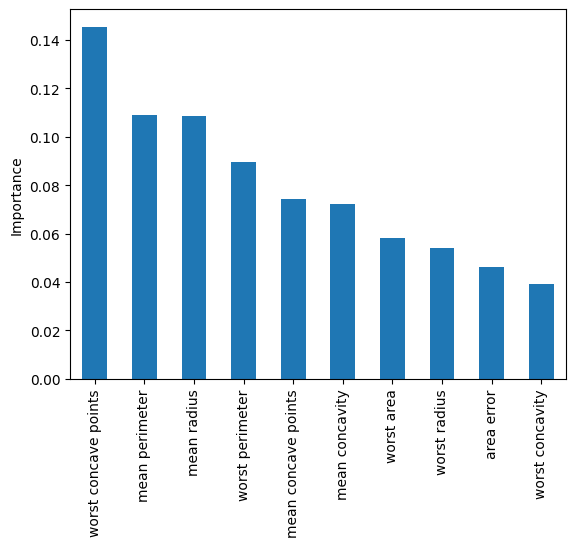

In [7]:
import matplotlib.pyplot as mat

# Show the 10 most important features
importance = pd.Series(best_forest.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(10).plot(kind='bar')

mat.ylabel('Importance')
mat.show()

Conclusion

I trained three models: Decision Tree, Random Forest and Gradient Boosting. Gradient Boosting gave the best accuracy (0.95).

I also tried tuning Random Forest with GridSearchCV. The tuned model reached 0.94 accuracy, so it didn't perform better than Gradient Boosting.

Overall, all three models gave good results, but Gradient Boosting worked best on this test set.